In [4]:
import json
import math
import os

import cv2
import shutil
from PIL import Image
import numpy as np
from keras import layers
from keras.applications import DenseNet121
from keras.callbacks import Callback, ModelCheckpoint
from keras.src.legacy.preprocessing.image import ImageDataGenerator
from keras.utils import array_to_img, img_to_array, load_img
from keras.models import Sequential
from keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score
import scipy
import tensorflow as tf
from tqdm import tqdm

%matplotlib inline

np.random.seed(2019)
tf.random.set_seed(2019)

Balanced dataset: (1180, 2)
Class counts: [236, 236, 236, 236, 236]

Augmented dataset: (6594, 2)

Diagnosis distribution:
diagnosis
0    1308
1    1318
2    1329
3    1321
4    1318
Name: count, dtype: int64


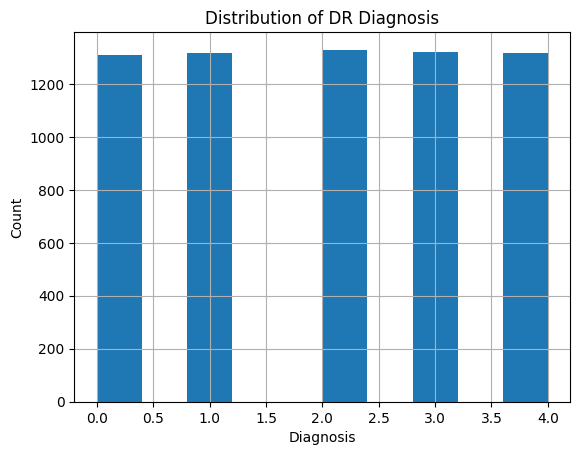

In [5]:

# Create clean output directories
import os
import shutil

base_dir = '/kaggle/working/ddr-equal'

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

os.makedirs(base_dir + '/train_images')
os.makedirs(base_dir + '/aug_images')

# Read original CSV
file_path = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv'
data = pd.read_csv(file_path)

dict = {}
LABEL_SIZE = 236

for i in data.index:
    dict[data['id_code'][i]] = data['diagnosis'][i]

count = [0, 0, 0, 0, 0]
rows = []

# Balance dataset and copy images
for i in data.index:
    source_file_path = (
        '/kaggle/input/datasets/mariaherrerot/ddrdataset/'
        'DR_grading/DR_grading/' + data['id_code'][i]
    )

    destination_file_path = base_dir + '/train_images/'

    if count[data['diagnosis'][i]] < LABEL_SIZE and os.path.exists(source_file_path):
        rows.append([data['id_code'][i], data['diagnosis'][i]])
        shutil.copy(source_file_path, destination_file_path)
        count[data['diagnosis'][i]] += 1

columns = ['id_code', 'diagnosis']

df = pd.DataFrame(rows, columns=columns)

# Save balanced CSV
file_path = base_dir + '/train.csv'
df.to_csv(file_path, index=False)

df1 = pd.read_csv(base_dir + '/train.csv')

print("Balanced dataset:", df1.shape)
print("Class counts:", count)

# Image augmentation
datagen = ImageDataGenerator(
    zoom_range=0.15,
    fill_mode='constant',
    cval=0.,
    horizontal_flip=True,
    vertical_flip=True,
)

for j in range(df1.shape[0]):
    id_code = df1['id_code'][j]
    diagnosis = str(df1['diagnosis'][j])

    img = load_img(base_dir + '/train_images/' + id_code)

    x = img_to_array(img)
    x = x.reshape((1,) + x.shape)

    i = 0

    for batch in datagen.flow(
        x,
        batch_size=1,
        save_to_dir=base_dir + '/aug_images',
        save_prefix=diagnosis + '_',
        save_format='jpg'
    ):
        i += 1
        if i > 5:
            break

# Create augmented CSV
augmented_rows = []
aug_dir = base_dir + '/aug_images'

for augmented_img_name in os.listdir(aug_dir):
    augmented_rows.append([
        augmented_img_name,
        int(augmented_img_name[0])
    ])

columns = ['id_code', 'diagnosis']

df_augmented = pd.DataFrame(augmented_rows, columns=columns)

output_csv_path = base_dir + '/aug.csv'
df_augmented.to_csv(output_csv_path, index=False)

# Load augmented dataset
train_df = pd.read_csv(base_dir + '/aug.csv')

print("\nAugmented dataset:", train_df.shape)

print("\nDiagnosis distribution:")
print(train_df['diagnosis'].value_counts().sort_index())

# Display histogram
train_df['diagnosis'].hist()

plt.title('Distribution of DR Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()


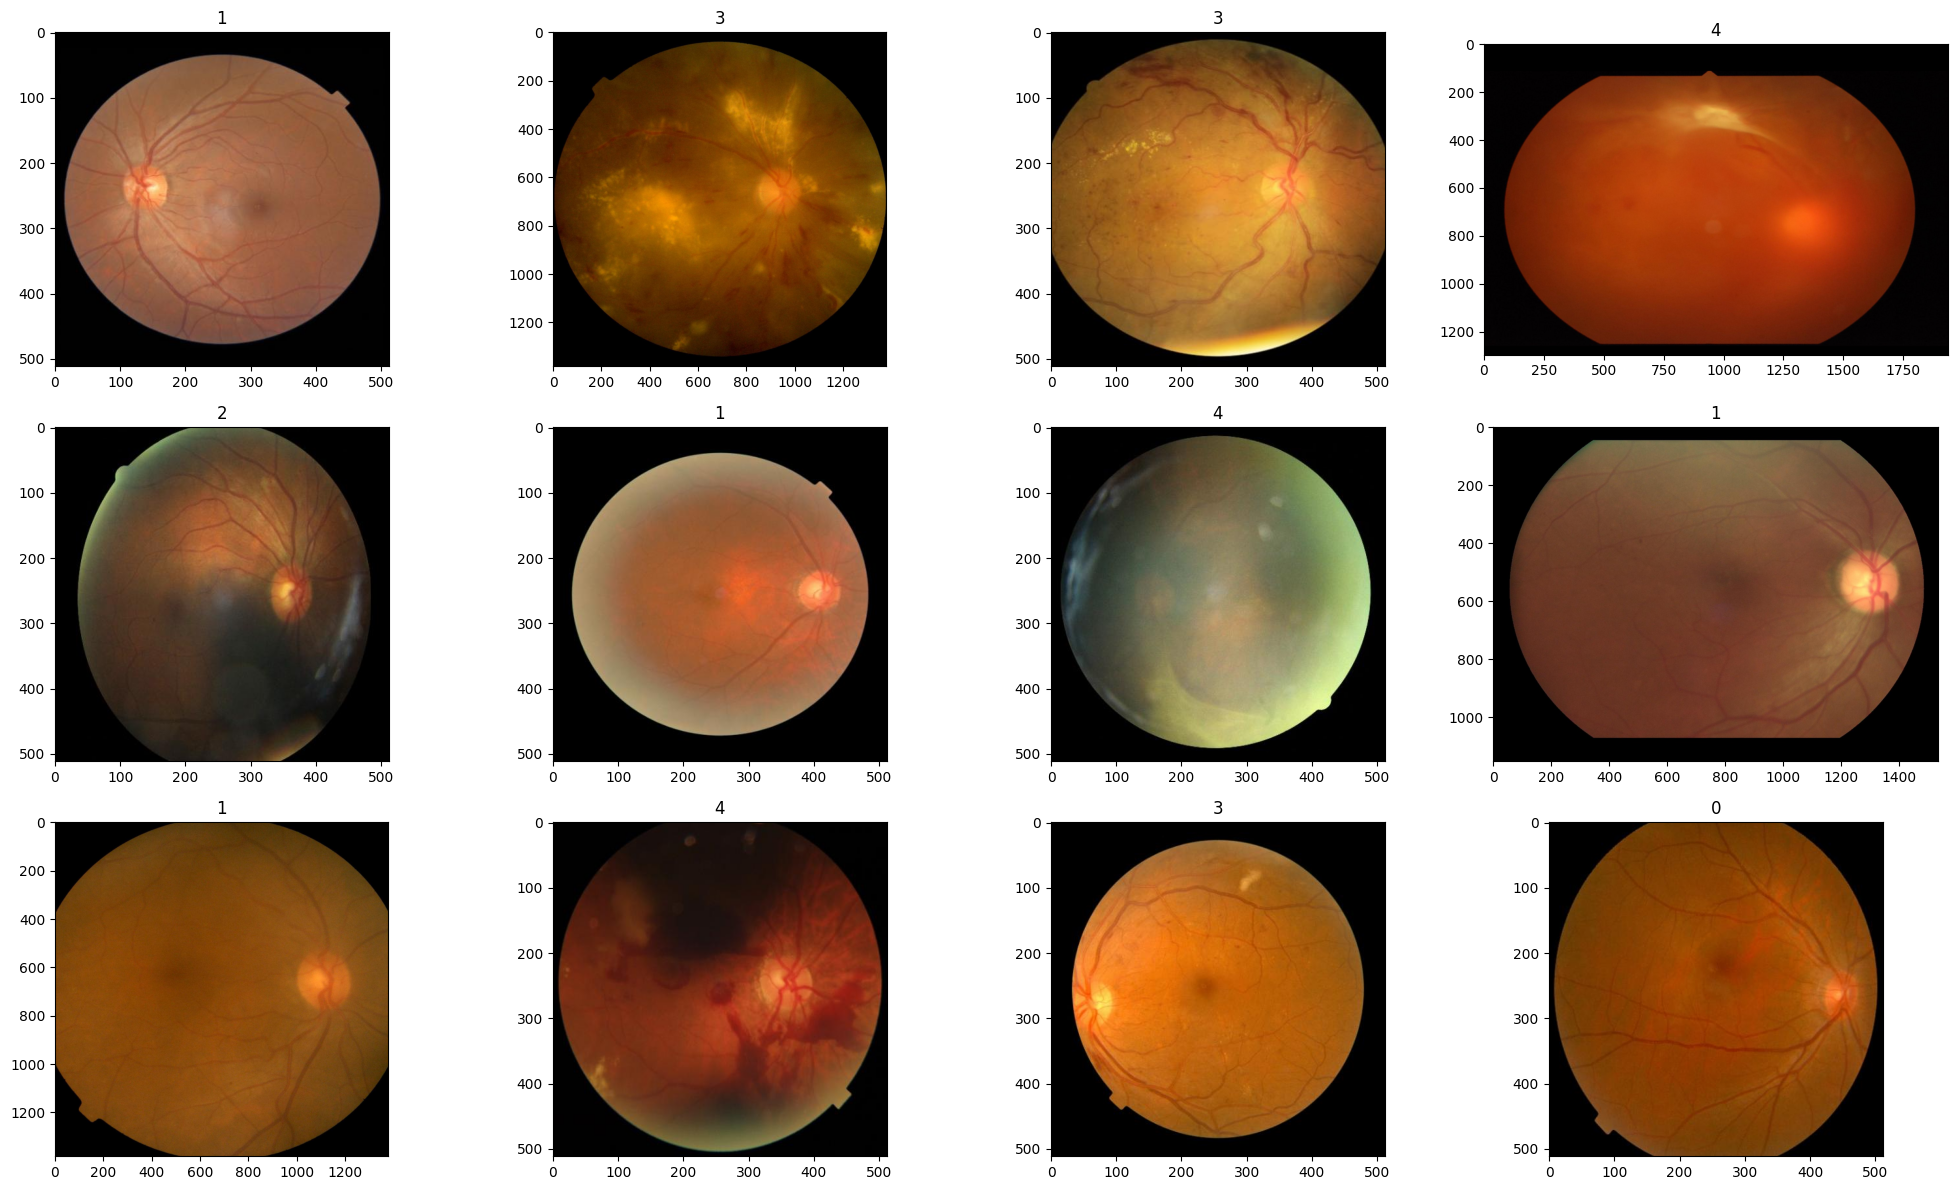

In [9]:
def display_samples(df, columns=4, rows=3):
    fig=plt.figure(figsize=(5*columns, 4*rows))

    for i in range(columns*rows):
        image_path = df.loc[i,'id_code']
        image_id = df.loc[i,'diagnosis']
        img = cv2.imread(f'/kaggle/working/ddr-equal/aug_images/{image_path}')
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        fig.add_subplot(rows, columns, i+1)
        plt.title(image_id)
        plt.imshow(img)
    
    plt.tight_layout()

display_samples(train_df)

In [10]:
def get_pad_width(im, new_shape, is_rgb=True):
    pad_diff = new_shape - im.shape[0], new_shape - im.shape[1]
    t, b = math.floor(pad_diff[0]/2), math.ceil(pad_diff[0]/2)
    l, r = math.floor(pad_diff[1]/2), math.ceil(pad_diff[1]/2)
    if is_rgb:
        pad_width = ((t,b), (l,r), (0, 0))
    else:
        pad_width = ((t,b), (l,r))
    return pad_width

def preprocess_image(image_path, desired_size=224):
    im = Image.open(image_path)
    im = im.resize((desired_size, )*2, resample=Image.LANCZOS)
    
    return im

N = train_df.shape[0]
x_train = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(train_df['id_code'])):
    x_train[i, :, :, :] = preprocess_image(
        f'/kaggle/working/ddr-equal/aug_images/{image_id}'
    )

y_train = pd.get_dummies(train_df['diagnosis']).values

print(x_train.shape)
print(y_train.shape)

y_train_multi = np.empty(y_train.shape, dtype=y_train.dtype)
y_train_multi[:, 4] = y_train[:, 4]

for i in range(3, -1, -1):
    y_train_multi[:, i] = np.logical_or(y_train[:, i], y_train_multi[:, i+1])

print("Original y_train:", y_train.sum(axis=0))
print("Multilabel version:", y_train_multi.sum(axis=0))

100%|██████████| 6594/6594 [03:18<00:00, 33.27it/s]

(6594, 224, 224, 3)
(6594, 5)
Original y_train: [1308 1318 1329 1321 1318]
Multilabel version: [6594 5286 3968 2639 1318]


In [11]:

y_train_multi = y_train_multi[:x_train.shape[0]]

x_train_full, x_test, y_train_full, y_test = train_test_split(
    x_train, y_train_multi,
    test_size=0.2,
    random_state=2019
)

x_train_partial, x_val, y_train_partial, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.1,
    random_state=2019
)

BATCH_SIZE = 32

def create_datagen():
    return ImageDataGenerator(
        zoom_range=0.15,
        fill_mode='constant',
        cval=0.,
        horizontal_flip=True,
        vertical_flip=True,
    )

data_generator = create_datagen().flow(
    x_train_partial,
    y_train_partial,
    batch_size=BATCH_SIZE,
    seed=2019
)

class Metrics(Callback):
    def on_train_begin(self, logs=None):
        self.val_kappas = []

    def on_epoch_end(self, epoch, logs=None):
        y_val = self.validation_data[:2][1]
        y_val = y_val.sum(axis=1) - 1

        X_val = self.validation_data[0]

        y_pred = self.model.predict(X_val, verbose=0) > 0.5
        y_pred = y_pred.astype(int).sum(axis=1) - 1

        _val_kappa = cohen_kappa_score(
            y_val,
            y_pred,
            weights='quadratic'
        )

        self.val_kappas.append(_val_kappa)

        print(f"val_kappa: {_val_kappa:.4f}")

        if _val_kappa == max(self.val_kappas):
            print("Validation Kappa has improved. Saving model.")
            self.model.save('model.keras')

# Updated DenseNet weights path
weights_path = '/kaggle/input/datasets/xhlulu/densenet-keras/DenseNet-BC-121-32-no-top.h5'

densenet = DenseNet121(
    weights=weights_path,
    include_top=False,
    input_shape=(224, 224, 3)
)

def build_model():
    model = Sequential()
    model.add(densenet)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(5, activation='sigmoid'))

    model.compile(
        loss='binary_crossentropy',
        optimizer=Adam(learning_rate=0.00005),
        metrics=['accuracy']
    )

    return model

model = build_model()
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,042,629 (26.87 MB)

 Trainable params: 6,958,981 (26.55 MB)

 Non-trainable params: 83,648 (326.75 KB)

Epoch 1/9
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5797 - loss: 0.5051
val_kappa: 0.7576
Validation Kappa has improved. Saving model.
207/207 ━━━━━━━━━━━━━━━━━━━━ 588s 2s/step - accuracy: 0.5899 - loss: 0.3610 - val_accuracy: 0.7860 - val_loss: 0.2765
Epoch 2/9
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.6165 - loss: 0.1991
val_kappa: 0.8198
Validation Kappa has improved. Saving model.
207/207 ━━━━━━━━━━━━━━━━━━━━ 101s 488ms/step - accuracy: 0.5940 - loss: 0.1747 - val_accuracy: 0.7330 - val_loss: 0.2011
Epoch 3/9
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.5857 - loss: 0.1244
val_kappa: 0.9485
Validation Kappa has improved. Saving model.
207/207 ━━━━━━━━━━━━━━━━━━━━ 97s 469ms/step - accuracy: 0.5743 - loss: 0.1151 - val_accuracy: 0.5000 - val_loss: 0.0785
Epoch 4/9
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.5474 - loss: 0.0790
val_kappa: 0.9613
Validation Kappa has improved. Saving model.
207/207 ━━━━━━━━━━━━━━━━━━━━ 97s 469ms/step 

<Axes: >

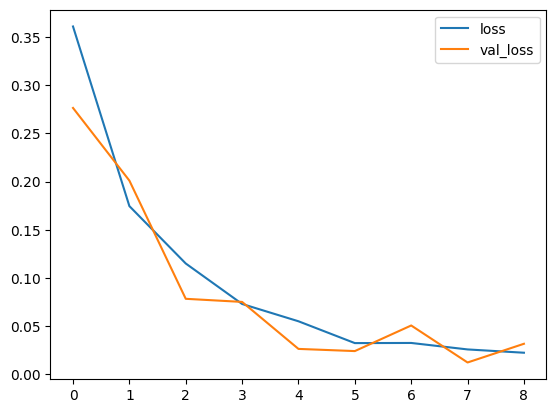

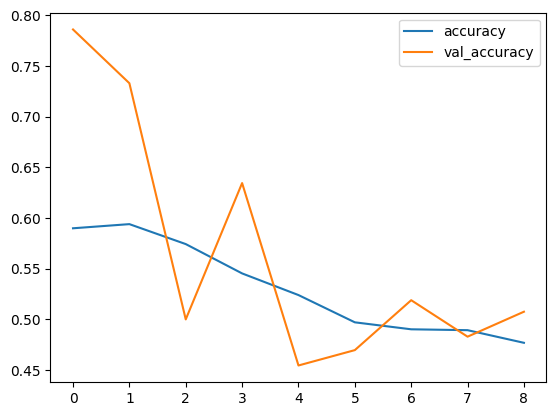

In [12]:

# Kappa metrics callback compatible with Keras 3

class Metrics(Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.X_val, self.y_val = validation_data
        self.val_kappas = []

    def on_epoch_end(self, epoch, logs=None):
        y_true = self.y_val.sum(axis=1) - 1

        y_pred = self.model.predict(
            self.X_val, verbose=0
        ) > 0.5

        y_pred = y_pred.astype(int).sum(axis=1) - 1

        val_kappa = cohen_kappa_score(
            y_true,
            y_pred,
            weights='quadratic'
        )

        self.val_kappas.append(val_kappa)

        print(f"\nval_kappa: {val_kappa:.4f}")

        if val_kappa >= max(self.val_kappas):
            print("Validation Kappa has improved. Saving model.")
            self.model.save('/kaggle/working/best_model.keras')


# Repeat the generator when its batches are exhausted
def repeat_generator(generator):
    while True:
        for batch in generator:
            yield batch


train_generator = repeat_generator(data_generator)

# Initialize callback with validation data
kappa_metrics = Metrics(validation_data=(x_val, y_val))

# Train model using original 207 steps
history = model.fit(
    train_generator,
    steps_per_epoch=int(np.ceil(x_train.shape[0] / BATCH_SIZE)),
    epochs=9,
    validation_data=(x_val, y_val),
    callbacks=[kappa_metrics]
)

# Save final model
model.save('/kaggle/working/densenet.keras')

# Test predictions
y_pred = model.predict(x_test) > 0.5
y_pred = y_pred.astype(int).sum(axis=1) - 1

y_true = y_test.sum(axis=1) - 1

print("Predictions shape:", y_pred.shape)
print("Actual labels shape:", y_true.shape)

# Save training history
with open('/kaggle/working/history.json', 'w') as f:
    json.dump(history.history, f)

# Plot loss
history_df = pd.DataFrame(history.history)
history_df[['loss', 'val_loss']].plot()

# Plot accuracy
history_df[['accuracy', 'val_accuracy']].plot()


In [13]:
print("x_train:", x_train.shape)
print("x_train_partial:", x_train_partial.shape)
print("x_val:", x_val.shape)
print("x_test:", x_test.shape)

print("Original steps:", x_train.shape[0] / BATCH_SIZE)
print("Partial training steps:", x_train_partial.shape[0] / BATCH_SIZE)

x_train: (6594, 224, 224, 3)
x_train_partial: (4747, 224, 224, 3)
x_val: (528, 224, 224, 3)
x_test: (1319, 224, 224, 3)
Original steps: 206.0625
Partial training steps: 148.34375


Confusion matrix:


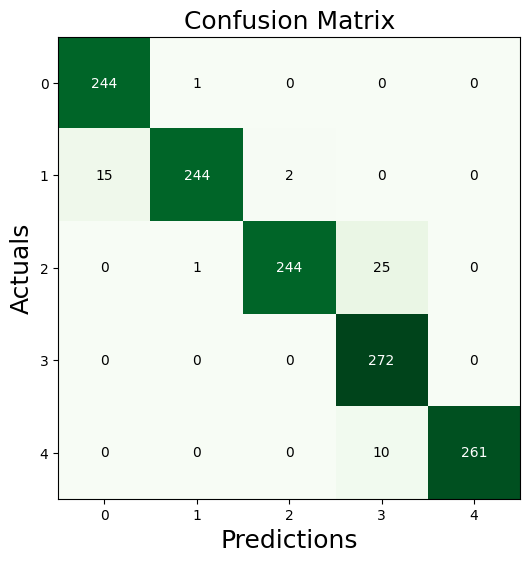

In [14]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_curve, auc
from mlxtend.plotting import plot_confusion_matrix

cm = confusion_matrix(y_true, y_pred) 
print('Confusion matrix:')
 
fig, ax = plot_confusion_matrix(conf_mat=cm, figsize=(6, 6), cmap=plt.cm.Greens)
plt.xlabel('Predictions', fontsize=18)
plt.ylabel('Actuals', fontsize=18)
plt.title('Confusion Matrix', fontsize=18)
plt.show()

In [15]:
accuracy = accuracy_score(y_true, y_pred) 
print('\nAccuracy : ', accuracy)


Accuracy :  0.959059893858984


In [16]:
macro_precision = precision_score(y_true, y_pred, average = 'macro') 
micro_precision = precision_score(y_true, y_pred, average = 'micro') 
weighted_precision = precision_score(y_true, y_pred, average = 'weighted') 

print('Macro Precision : ', macro_precision)
print('Micro Precision : ', micro_precision)
print('Weighted Precision : ', weighted_precision)

macro_recall = recall_score(y_true, y_pred, average = 'macro') 
micro_recall = recall_score(y_true, y_pred, average = 'micro') 
weighted_recall = recall_score(y_true, y_pred, average = 'weighted') 

print('Macro recall : ', macro_recall)
print('Micro recall : ', micro_recall)
print('Weighted recall : ', weighted_recall)

macro_f1 = f1_score(y_true, y_pred, average = 'macro') 
micro_f1 = f1_score(y_true, y_pred, average = 'micro') 
weighted_f1 = f1_score(y_true, y_pred, average = 'weighted') 

print('Macro f1 : ', macro_f1)
print('Micro f1 : ', micro_f1)
print('Weighted f1 : ', weighted_f1)

Macro Precision :  0.9623636529650671
Micro Precision :  0.959059893858984
Weighted Precision :  0.9624594129288161
Macro recall :  0.9595175204860189
Micro recall :  0.959059893858984
Weighted recall :  0.959059893858984
Macro f1 :  0.9594538029254569
Micro f1 :  0.959059893858984
Weighted f1 :  0.9592523637277273


In [18]:
import shutil
import os

shutil.make_archive(
    "/kaggle/working/DR_Project_Backup",
    "zip",
    "/kaggle/working"
)

print("Project backup created!")

Project backup created!


In [40]:
import os
import pandas as pd

# Original DDR dataset
csv_path = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv'

image_dir = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading/'

# Load original dataset
original_df = pd.read_csv(csv_path)

# Check class distribution
print("Total records:", len(original_df))

print("\nOriginal class distribution:")
print(original_df['diagnosis'].value_counts().sort_index())

# Check missing images
missing_images = [
    image_id for image_id in original_df['id_code']
    if not os.path.exists(os.path.join(image_dir, image_id))
]

print("\nMissing images:", len(missing_images))
print("Available images:", len(original_df) - len(missing_images))

# Check duplicate image IDs
print("Duplicate image IDs:", original_df['id_code'].duplicated().sum())

Total records: 12522

Original class distribution:
diagnosis
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64

Missing images: 0
Available images: 12522
Duplicate image IDs: 0


In [20]:
print("Dataset columns:")
print(original_df.columns.tolist())

print("\nFirst five records:")
display(original_df.head())

print("\nDuplicate image IDs:")
print(original_df['id_code'].duplicated().sum())

Dataset columns:
['id_code', 'diagnosis']

First five records:


,id_code,diagnosis
0,20170413102628830.jpg,0
1,20170413111955404.jpg,0
2,20170413112015395.jpg,0
3,20170413112017305.jpg,0
4,20170413112528859.jpg,0



Duplicate image IDs:
0


In [21]:
from sklearn.model_selection import train_test_split

# Work with original dataset only
df = original_df.copy()

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=2019,
    stratify=df['diagnosis']
)

# Second split: 10% validation, 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=2019,
    stratify=temp_df['diagnosis']
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display results
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
print(train_df['diagnosis'].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df['diagnosis'].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df['diagnosis'].value_counts().sort_index())

# Verify no image overlap
assert set(train_df.id_code).isdisjoint(val_df.id_code)
assert set(train_df.id_code).isdisjoint(test_df.id_code)
assert set(val_df.id_code).isdisjoint(test_df.id_code)

print("\nSUCCESS: No image overlap between splits.")

Training images: 10017
Validation images: 1252
Testing images: 1253

Training distribution:
diagnosis
0    5013
1     504
2    3581
3     189
4     730
Name: count, dtype: int64

Validation distribution:
diagnosis
0    626
1     63
2    448
3     24
4     91
Name: count, dtype: int64

Testing distribution:
diagnosis
0    627
1     63
2    448
3     23
4     92
Name: count, dtype: int64

SUCCESS: No image overlap between splits.


In [22]:
import numpy as np
from PIL import Image
from tqdm.notebook import tqdm
import os

IMAGE_DIR = '/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading/'

IMAGE_SIZE = 224

def load_images(dataframe):
    images = np.empty(
        (len(dataframe), IMAGE_SIZE, IMAGE_SIZE, 3),
        dtype=np.uint8
    )

    for i, image_id in enumerate(tqdm(dataframe['id_code'])):
        image_path = os.path.join(IMAGE_DIR, image_id)

        img = Image.open(image_path).convert('RGB')
        img = img.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.LANCZOS
        )

        images[i] = np.asarray(img)

    return images

# Load each split independently
x_train = load_images(train_df)
x_val = load_images(val_df)
x_test = load_images(test_df)

# Original class labels
y_train = train_df['diagnosis'].to_numpy()
y_val = val_df['diagnosis'].to_numpy()
y_test = test_df['diagnosis'].to_numpy()

print("\nDataset shapes:")
print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)

  0%|          | 0/10017 [00:00<?, ?it/s]

  0%|          | 0/1252 [00:00<?, ?it/s]

  0%|          | 0/1253 [00:00<?, ?it/s]


Dataset shapes:
Training: (10017, 224, 224, 3) (10017,)
Validation: (1252, 224, 224, 3) (1252,)
Testing: (1253, 224, 224, 3) (1253,)


In [25]:
# Convert grades into cumulative ordinal targets

def create_ordinal_labels(labels):
    return np.array([
        [int(i <= grade) for i in range(5)]
        for grade in labels
    ], dtype=np.float32)

y_train_multi = create_ordinal_labels(y_train)
y_val_multi = create_ordinal_labels(y_val)
y_test_multi = create_ordinal_labels(y_test)

print("Training labels:", y_train_multi.shape)
print("Validation labels:", y_val_multi.shape)
print("Testing labels:", y_test_multi.shape)

print("\nOrdinal encoding verification:")
for grade in range(5):
    print(grade, ":", y_train_multi[y_train == grade][0])

Training labels: (10017, 5)
Validation labels: (1252, 5)
Testing labels: (1253, 5)

Ordinal encoding verification:
0 : [0. 0. 0. 0. 0.]
1 : [1. 0. 0. 0. 0.]
2 : [1. 1. 0. 0. 0.]
3 : [1. 1. 1. 0. 0.]
4 : [1. 1. 1. 1. 0.]


In [27]:
expected = [
    [1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0],
    [1, 1, 1, 0, 0],
    [1, 1, 1, 1, 0],
    [1, 1, 1, 1, 1]
]

for grade in range(5):
    actual = y_train_multi[y_train == grade][0]

    assert np.array_equal(actual, expected[grade]), (
        f"Encoding error in grade {grade}"
    )

print("All five ordinal encodings verified successfully!")

All five ordinal encodings verified successfully!


In [29]:
# Restore Python's built-in dictionary function
del dict

print("Built-in dict restored:", type(dict))

Built-in dict restored: <class 'type'>


In [30]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Training-only augmentation
train_datagen = ImageDataGenerator(
    zoom_range=0.15,
    fill_mode='constant',
    cval=0.0,
    horizontal_flip=True,
    vertical_flip=True
)

BATCH_SIZE = 32

train_generator = train_datagen.flow(
    x_train,
    y_train_multi,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=2019
)

# Calculate class weights using original training labels
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
for grade, weight in class_weights.items():
    print(f"Grade {grade}: {weight:.4f}")

print("\nTraining batches per epoch:", len(train_generator))
print("Validation images:", len(x_val))
print("Test images:", len(x_test))

Class weights:
Grade 0: 0.3996
Grade 1: 3.9750
Grade 2: 0.5595
Grade 3: 10.6000
Grade 4: 2.7444

Training batches per epoch: 314
Validation images: 1252
Test images: 1253


In [31]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

weights_path = (
    '/kaggle/input/datasets/xhlulu/densenet-keras/'
    'DenseNet-BC-121-32-no-top.h5'
)

# Load pretrained DenseNet121
densenet = DenseNet121(
    weights=weights_path,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone for initial training
densenet.trainable = False

# Build model
model = models.Sequential([
    densenet,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(5, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=0.00005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,042,629 (26.87 MB)

 Trainable params: 5,125 (20.02 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [32]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger, Callback
from sklearn.metrics import cohen_kappa_score

SAVE_DIR = "/kaggle/working/DR_Final_Experiment"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save model after every completed epoch
checkpoint = ModelCheckpoint(
    filepath=SAVE_DIR + "/latest_model.keras",
    save_best_only=False,
    save_weights_only=False,
    verbose=1
)

# Save best model based on validation QWK
class QWKCallback(Callback):

    def __init__(self, x_val, y_val):
        super().__init__()
        self.x_val = x_val
        self.y_val = y_val
        self.best_qwk = -1

    def on_epoch_end(self, epoch, logs=None):

        predictions = self.model.predict(
            self.x_val,
            batch_size=32,
            verbose=0
        )

        predicted_grades = (predictions > 0.5).sum(axis=1)
        actual_grades = self.y_val.sum(axis=1)

        qwk = cohen_kappa_score(
            actual_grades,
            predicted_grades,
            weights="quadratic"
        )

        print(f"\nValidation QWK: {qwk:.4f}")

        if qwk > self.best_qwk:
            self.best_qwk = qwk
            self.model.save(SAVE_DIR + "/best_model.keras")
            print("Best model saved.")

qwk_callback = QWKCallback(x_val, y_val_multi)

csv_logger = CSVLogger(
    SAVE_DIR + "/training_history.csv",
    append=True
)

print("Checkpoint and recovery system ready.")

Checkpoint and recovery system ready.


In [33]:
history = model.fit(
    train_generator,
    epochs=9,
    validation_data=(x_val, y_val_multi),
    callbacks=[
        checkpoint,
        qwk_callback,
        csv_logger
    ]
)

Epoch 1/9
314/314 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.5832 - loss: 3.0812
Epoch 1: saving model to /kaggle/working/DR_Final_Experiment/latest_model.keras

Epoch 1: finished saving model to /kaggle/working/DR_Final_Experiment/latest_model.keras

Validation QWK: -0.0265
Best model saved.
314/314 ━━━━━━━━━━━━━━━━━━━━ 246s 701ms/step - accuracy: 0.7349 - loss: 2.3385 - val_accuracy: 1.0000 - val_loss: 0.6693
Epoch 2/9
314/314 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.8902 - loss: 1.5603
Epoch 2: saving model to /kaggle/working/DR_Final_Experiment/latest_model.keras

Epoch 2: finished saving model to /kaggle/working/DR_Final_Experiment/latest_model.keras

Validation QWK: 0.0942
Best model saved.
314/314 ━━━━━━━━━━━━━━━━━━━━ 153s 487ms/step - accuracy: 0.9078 - loss: 1.5383 - val_accuracy: 1.0000 - val_loss: 0.6188
Epoch 3/9
314/314 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.9449 - loss: 1.4128
Epoch 3: saving model to /kaggle/working/DR_Final_Experiment/latest_mode

In [34]:
import shutil
import os

shutil.make_archive(
    "/kaggle/working/DR_Final_Experiment_Backup",
    "zip",
    "/kaggle/working/DR_Final_Experiment"
)

print("Training backup created successfully.")

Training backup created successfully.


In [35]:
import os

for item in os.listdir("/kaggle/working"):
    path = os.path.join("/kaggle/working", item)
    print(item, "—", "Folder" if os.path.isdir(path) else "File")

ddr-equal — Folder
DR_Project_Backup.zip — File
.virtual_documents — Folder
best_model.keras — File
densenet.keras — File
DR_Final_Experiment_Backup.zip — File
DR_Final_Experiment — Folder
history.json — File
